# Exploração Trabalho 
Aqui vamos explorar os dados rellacionados a postos de trabalho criados e ocupação de pessoas imigrantes no Brasil. Dados fornecidos pelo CAGED obtidos em (https://www.gov.br/mj/pt-br/assuntos/seus-direitos/migracoes/portal-de-imigracao-laboral/obmigra-1/microdados/caged/CAGED)

In [1]:
# Carregando uma amostra do CAGED 2025

import pandas as pd
from pathlib import Path

pasta = Path("../data/raw/trabalho")

for arquivo in pasta.rglob("*.csv"):
    print(arquivo.name)

RAIS_CTPS_CAGED_2025_MOV.csv
RAIS_CTPS_CAGED_2026_MOV.csv
RAIS_CTPS_ESTOQUE_2025.csv
cbo2002-ocupacao.csv
codigos_ocupacao_cbo.csv
cnae_classes.csv
cnae_grupos.csv
cnae_secoes.csv
cnae_subclasses.csv


In [2]:
# Lendo as primeiras linhas do CAGED 2025

df_2025 = pd.read_csv(
    pasta / "RAIS_CTPS_CAGED_2025_MOV.csv",
    sep = ";",
    encoding = "utf-8",
    low_memory = False
)

display(df_2025.head(5))

,competenciamov,saldomovimentacao,pais,continente,uf,municipio,cbo2002ocupacao,subclasse,secao,categoria,...,nivel_instrucao,salario,faixa_etaria,racacor,faixa_horas_contrat,indtrabparcial,indtrabintermitente,tipomovimentacao,unidadesalariocodigo,valorsalariofixo
0,202501,1,NATURALIDADE BRASILEIRA,AMÉRICA DO SUL,11,110002,414110,4744001,G,101,...,4,1580.00,03,3,6,0,0,97,5,1580.00
1,202501,1,NATURALIDADE BRASILEIRA,AMÉRICA DO SUL,11,110002,521130,4771701,G,101,...,4,1600.00,03,1,6,0,0,97,5,1600.00
2,202501,-1,VENEZUELA,AMÉRICA DO SUL,11,110002,514120,4789004,G,101,...,4,908.75,05,3,4,0,0,31,1,7.27
3,202501,1,VENEZUELA,AMÉRICA DO SUL,11,110002,513435,5611203,I,101,...,4,1605.00,02,2,6,0,0,97,5,1605.00
4,202501,-1,VENEZUELA,AMÉRICA DO SUL,11,110002,783225,4930202,H,101,...,2,1735.76,05,2,6,0,0,40,5,1735.76


In [3]:
# Verificando a coluna "saldomovimentacao" pra inconsistências

print(df_2025["saldomovimentacao"].value_counts(dropna=False))

saldomovimentacao
 1    427345
-1    347249
Name: count, dtype: int64


In [4]:
# Verificando a distribuição mensal de movimentações

df_2025["competenciamov"].value_counts().sort_index()

competenciamov
202501    65722
202502    70004
202503    64319
202504    62647
202505    62262
202506    60598
202507    65833
202508    64176
202509    65951
202510    69853
202511    62790
202512    60439
Name: count, dtype: int64

### Verificar os códigos dos municípios
No SISMIGRA, utilizamos códigos IBGE de 7 dígitos. Já no CAGED, o exemplo 110002 possui apenas 6 dígitos.

In [5]:
print(df_2025["municipio"].astype(str).str.len().value_counts())

print("\nExemplos de códigos:")
print(df_2025["municipio"].unique()[:15])

municipio
6    774594
Name: count, dtype: int64

Exemplos de códigos:
[110002 110004 110007 110009 110010 110012 110018 110020 110028 110030
 110045 110092 120040 130185 130190]


Não devemos simplesmente acrescentar um número ao código. Vamos criar uma tabela de correspondência usando os códigos oficiais do IBGE que já baixamos.

In [6]:
# Carregando a tabela municipios_ibge criada no notebook 01 e salva em /processed

ibge_municipios = pd.read_parquet(
    "../data/processed/municipios_ibge.parquet"
)

# Criando código de 6 dígitos utilizado pelo CAGED 

ibge_municipios["codigo_caged"] = (
    ibge_municipios["codigo_ibge"] // 10

)

display(ibge_municipios.head())

# Verificando se há códigos duplicados 

print(
    "Códigos CAGED duplicados:",
    ibge_municipios["codigo_caged"].duplicated().sum()
)

,codigo_ibge,municipio,uf,codigo_caged
0,1100015,ALTA FLORESTA D'OESTE,RO,110001
1,1100023,ARIQUEMES,RO,110002
2,1100031,CABIXI,RO,110003
3,1100049,CACOAL,RO,110004
4,1100056,CEREJEIRAS,RO,110005


Códigos CAGED duplicados: 0


In [7]:
# Associando o CAGED 2025 aos códigos IBGE

df_2025 = df_2025.merge(
    ibge_municipios[["codigo_caged", "codigo_ibge"]],
    left_on="municipio",
    right_on="codigo_caged",
    how="left",
    validate="many_to_one"
)

print("Total de registros:", len(df_2025))
print("Com código IBGE:", df_2025["codigo_ibge"].notna().sum())
print("Sem código IBGE:", df_2025["codigo_ibge"].isna().sum())


Total de registros: 774594
Com código IBGE: 709021
Sem código IBGE: 65573


In [8]:
# Identificando os códigos não encontrados

df_2025[df_2025["codigo_ibge"].isna()]["municipio"].value_counts().head(20)

municipio
999999    65573
Name: count, dtype: int64

In [9]:
# Excluindo da análise municipal os registros onde "municipio" == 999999

df_2025 = df_2025.dropna(
    subset=["codigo_ibge"]
).copy()

print("Registros restantes:", len(df_2025))

Registros restantes: 709021


### Calcular admissões, demissões e saldo por município

In [10]:
emprego_2025 = df_2025.groupby("codigo_ibge").agg(
    admissoes=("saldomovimentacao", lambda x: (x == 1).sum()),
    desligamentos=("saldomovimentacao", lambda x: (x == -1).sum()),
    saldo=("saldomovimentacao", "sum")
).reset_index()

display(emprego_2025.head(10))

,codigo_ibge,admissoes,desligamentos,saldo
0,1100023.0,34,18,16
1,1100049.0,160,141,19
2,1100056.0,10,0,10
3,1100072.0,22,29,-7
4,1100098.0,40,45,-5
5,1100106.0,26,16,10
6,1100114.0,12,0,12
7,1100122.0,298,213,85
8,1100189.0,58,55,3
9,1100205.0,534,451,83


In [11]:
# Adicionando os nomes dos municípios e UFs

emprego_2025 = emprego_2025.merge(
    ibge_municipios[["codigo_ibge", "municipio", "uf"]],
    on="codigo_ibge",
    how="left"
)

emprego_2025 = emprego_2025[["codigo_ibge", "municipio", "uf", "admissoes", "desligamentos", "saldo"]]

display(
    emprego_2025.sort_values("admissoes", ascending=False).head(20)
)

,codigo_ibge,municipio,uf,admissoes,desligamentos,saldo
391,3550308.0,SÃO PAULO,SP,34987,28503,6484
453,4106902.0,CURITIBA,PR,34733,27313,7420
597,4204202.0,CHAPECÓ,SC,12807,10391,2416
439,4104808.0,CASCAVEL,PR,11027,9088,1939
647,4209102.0,JOINVILLE,SC,10862,9020,1842
772,4305108.0,CAXIAS DO SUL,RS,10164,8748,1416
609,4205407.0,FLORIANÓPOLIS,SC,8762,7253,1509
22,1400100.0,BOA VISTA,RR,7464,6849,615
17,1302603.0,MANAUS,AM,5587,5086,501
917,4322509.0,VACARIA,RS,5232,5046,186


In [12]:
# Validando os totais

print("Registros originais: ", len(df_2025))

print("Admissões + desligamentos:", emprego_2025["admissoes"].sum() + emprego_2025["desligamentos"].sum())

print("Saldo total:", emprego_2025["saldo"].sum())

Registros originais:  709021
Admissões + desligamentos: 709021
Saldo total: 77909


### Analisando os dados de 2026

In [13]:
# Carregando o DataFrame de 2026

df_2026 = pd.read_csv(
    pasta / "RAIS_CTPS_CAGED_2026_MOV.csv",
    sep = ";",
    encoding = "utf-8",
    low_memory=False
)

# Analisando os meses de 2026

print("Total de registros:", len(df_2026))
print("\nMovimentações por mês:")
print(df_2026["competenciamov"].value_counts().sort_index())

Total de registros: 550029

Movimentações por mês:
competenciamov
202601    75862
202602    82292
202603    88026
202604    77307
202605    74554
202606    74016
202607    77972
Name: count, dtype: int64


In [14]:
# Comparando os períodos entre 2025 e 2026

# Selecionando janeiro a julho de 2025

caged_2025_jul = df_2025[
    df_2025["competenciamov"].between(202501, 202507)
]

for ano, df in [(2025, caged_2025_jul), (2026, df_2026)]:
    print(f"\n{ano}")
    print("Admissões:", (df["saldomovimentacao"] == 1).sum())
    print("Desligamentos:", (df["saldomovimentacao"] == -1).sum())
    print("Saldo:", df["saldomovimentacao"].sum())


2025
Admissões: 231492
Desligamentos: 181985
Saldo: 49507

2026
Admissões: 302786
Desligamentos: 247243
Saldo: 55543


In [15]:
# Padronizando os municípios de 2026

df_2026 = df_2026.merge(
    ibge_municipios[["codigo_caged", "codigo_ibge"]],
    left_on="municipio",
    right_on="codigo_caged", 
    how="left",
    validate="many_to_one"
)

print("Total de resigstos:", len(df_2026))
print("Com código IBGE:", df_2026["codigo_ibge"].notna().sum())
print("Sem código IBGE:", df_2026["codigo_ibge"].isna().sum())

Total de resigstos: 550029
Com código IBGE: 496488
Sem código IBGE: 53541


In [16]:
#Verificando os registros nos dados de 2026 onde não há código IBGE

df_2026[df_2026["codigo_ibge"].isna()]["municipio"].value_counts().head(20)

municipio
999999    53541
Name: count, dtype: int64

In [17]:
# Excluindo da análise municipal os registros onde "municipio" == 999999

df_2026 = df_2026.dropna(
    subset=["codigo_ibge"]
).copy()

print("Registros restantes:", len(df_2026))

Registros restantes: 496488


In [18]:
# Comparando janeiro a julho dos dois anos, considerando apenas movimentaç~es com municipio identificado

for ano, df in [(2025, caged_2025_jul), (2026, df_2026)]:
    admissoes = (df["saldomovimentacao"] == 1).sum()
    desligamentos = (df["saldomovimentacao"] == -1).sum()

    print(f"\n{ano} (jan-jul)")
    print("Admissões:", admissoes)
    print("Desligamentos:", desligamentos)
    print("Saldo:", admissoes - desligamentos)


2025 (jan-jul)
Admissões: 231492
Desligamentos: 181985
Saldo: 49507

2026 (jan-jul)
Admissões: 275160
Desligamentos: 221328
Saldo: 53832


In [19]:
# Calculando indicadores municipais de 2026

emprego_2026 = df_2026.groupby("codigo_ibge").agg(
    admissoes=("saldomovimentacao", lambda x: (x == 1).sum()),
    desligamentos=("saldomovimentacao", lambda x: (x == -1).sum()),
    saldo=("saldomovimentacao", "sum")
).reset_index()

display(emprego_2026.head(10))

,codigo_ibge,admissoes,desligamentos,saldo
0,1100023.0,15,0,15
1,1100049.0,85,84,1
2,1100072.0,12,0,12
3,1100098.0,23,26,-3
4,1100106.0,19,20,-1
5,1100122.0,181,129,52
6,1100189.0,36,15,21
7,1100205.0,356,308,48
8,1100288.0,83,73,10
9,1100304.0,221,162,59


In [20]:
# Adicionando os nomes dos municípios e UFs à tabela de 2026

emprego_2026 = emprego_2026.merge(
    ibge_municipios[["codigo_ibge", "municipio", "uf"]],
    on="codigo_ibge",
    how="left"
)

emprego_2026 = emprego_2026[["codigo_ibge", "municipio", "uf", "admissoes", "desligamentos", "saldo"]]

display(
    emprego_2026.sort_values("admissoes", ascending=False).head(20)
)

,codigo_ibge,municipio,uf,admissoes,desligamentos,saldo
316,3550308.0,SÃO PAULO,SP,23796,19629,4167
371,4106902.0,CURITIBA,PR,23209,19263,3946
497,4204202.0,CHAPECÓ,SC,8679,7169,1510
547,4209102.0,JOINVILLE,SC,7803,6413,1390
661,4305108.0,CAXIAS DO SUL,RS,7528,6321,1207
358,4104808.0,CASCAVEL,PR,7322,6109,1213
19,1400100.0,BOA VISTA,RR,5562,4744,818
509,4205407.0,FLORIANÓPOLIS,SC,5345,4924,421
784,4322509.0,VACARIA,RS,5012,4412,600
15,1302603.0,MANAUS,AM,3388,3042,346


In [21]:
# Criando uma tabela equivalente para janeiro a julho de 2025, comparando municípios no mesmo período

emprego_2025_jul = caged_2025_jul.groupby("codigo_ibge").agg(
    admissoes=("saldomovimentacao", lambda x: (x == 1).sum()),
    desligamentos=("saldomovimentacao", lambda x: (x == -1).sum()),
    saldo=("saldomovimentacao", "sum")
).reset_index()

display(emprego_2025_jul.head())

,codigo_ibge,admissoes,desligamentos,saldo
0,1100023.0,21,11,10
1,1100049.0,91,82,9
2,1100056.0,10,0,10
3,1100072.0,10,6,4
4,1100098.0,25,32,-7


In [22]:
# Juntando os indicadores municipais entre 2025 e 2026, usando o código do IBGE

comparacao_emprego = emprego_2025_jul.merge(
    emprego_2026,
    on="codigo_ibge",
    how="outer",
    suffixes=("_2025", "_2026")
)

display(comparacao_emprego.head(10))

,codigo_ibge,admissoes_2025,desligamentos_2025,saldo_2025,municipio,uf,admissoes_2026,desligamentos_2026,saldo_2026
0,1100023.0,21.0,11.0,10.0,ARIQUEMES,RO,15.0,0.0,15.0
1,1100049.0,91.0,82.0,9.0,CACOAL,RO,85.0,84.0,1.0
2,1100056.0,10.0,0.0,10.0,NaN,NaN,NaN,NaN,NaN
3,1100072.0,10.0,6.0,4.0,CORUMBIARA,RO,12.0,0.0,12.0
4,1100098.0,25.0,32.0,-7.0,ESPIGÃO D'OESTE,RO,23.0,26.0,-3.0
5,1100106.0,17.0,8.0,9.0,GUAJARÁ-MIRIM,RO,19.0,20.0,-1.0
6,1100114.0,8.0,0.0,8.0,NaN,NaN,NaN,NaN,NaN
7,1100122.0,169.0,113.0,56.0,JI-PARANÁ,RO,181.0,129.0,52.0
8,1100189.0,42.0,39.0,3.0,PIMENTA BUENO,RO,36.0,15.0,21.0
9,1100205.0,301.0,257.0,44.0,PORTO VELHO,RO,356.0,308.0,48.0


In [23]:
# Tratando valores ausentes 

colunas = [
    "admissoes_2025", "desligamentos_2025", "saldo_2025",
    "admissoes_2026", "desligamentos_2026", "saldo_2026",
]

comparacao_emprego[colunas] = comparacao_emprego[colunas].fillna(0)

display(comparacao_emprego.head(10))

,codigo_ibge,admissoes_2025,desligamentos_2025,saldo_2025,municipio,uf,admissoes_2026,desligamentos_2026,saldo_2026
0,1100023.0,21.0,11.0,10.0,ARIQUEMES,RO,15.0,0.0,15.0
1,1100049.0,91.0,82.0,9.0,CACOAL,RO,85.0,84.0,1.0
2,1100056.0,10.0,0.0,10.0,NaN,NaN,0.0,0.0,0.0
3,1100072.0,10.0,6.0,4.0,CORUMBIARA,RO,12.0,0.0,12.0
4,1100098.0,25.0,32.0,-7.0,ESPIGÃO D'OESTE,RO,23.0,26.0,-3.0
5,1100106.0,17.0,8.0,9.0,GUAJARÁ-MIRIM,RO,19.0,20.0,-1.0
6,1100114.0,8.0,0.0,8.0,NaN,NaN,0.0,0.0,0.0
7,1100122.0,169.0,113.0,56.0,JI-PARANÁ,RO,181.0,129.0,52.0
8,1100189.0,42.0,39.0,3.0,PIMENTA BUENO,RO,36.0,15.0,21.0
9,1100205.0,301.0,257.0,44.0,PORTO VELHO,RO,356.0,308.0,48.0


In [24]:
# Completando os nomes dos municípios e UFs que estavam NaN, utilizando a tabela do IBGE

nomes = ibge_municipios.set_index("codigo_ibge")

comparacao_emprego["municipio"] = (
    comparacao_emprego["municipio"].fillna(
        comparacao_emprego["codigo_ibge"].map(nomes["municipio"])
    )
)

comparacao_emprego["uf"] = (
    comparacao_emprego["uf"].fillna(
        comparacao_emprego["codigo_ibge"].map(nomes["uf"])
    )
)

print(comparacao_emprego[["municipio", "uf"]].isna().sum())

municipio    0
uf           0
dtype: int64


Calculando a variação das admissões por município entre janeiro e julho de 2025 e 2026

In [25]:
comparacao_emprego["variacao_absoluta"] = (
    comparacao_emprego["admissoes_2026"] - comparacao_emprego["admissoes_2025"]
)

comparacao_emprego["variacao_%"] = (
    comparacao_emprego["variacao_absoluta"] / comparacao_emprego["admissoes_2025"].replace(0, float("nan")) * 100
)

display(
    comparacao_emprego[["uf", "municipio", "admissoes_2025", "admissoes_2026", "variacao_absoluta", "variacao_%"]].sort_values(
        "variacao_absoluta", ascending=False
    ).head(20)
)

,uf,municipio,admissoes_2025,admissoes_2026,variacao_absoluta,variacao_%
412,SP,SÃO PAULO,19828.0,23796.0,3968.0,20.012104
476,PR,CURITIBA,20000.0,23209.0,3209.0,16.045000
24,RR,BOA VISTA,4100.0,5562.0,1462.0,35.658537
673,SC,JOINVILLE,6549.0,7803.0,1254.0,19.147962
955,RS,VACARIA,3908.0,5012.0,1104.0,28.249744
635,SC,FLORIANÓPOLIS,4357.0,5345.0,988.0,22.676153
623,SC,CHAPECÓ,7698.0,8679.0,981.0,12.743570
805,RS,CAXIAS DO SUL,6564.0,7528.0,964.0,14.686167
462,PR,CASCAVEL,6524.0,7322.0,798.0,12.231760
1022,MT,CUIABÁ,2525.0,3256.0,731.0,28.950495


In [26]:
# Validando os totais

for ano, df in[(2025, caged_2025_jul), (2026, df_2026)]:
    original = (df["saldomovimentacao"] == 1).sum()
    consolidado = comparacao_emprego[f"admissoes_{ano}"].sum()

    print(f"{ano}:")
    print("Original:", original)
    print("Consolidado:", int(consolidado))
    print("Diferença:", int(original - consolidado), "\n")

                                     

2025:
Original: 231492
Consolidado: 231492
Diferença: 0 

2026:
Original: 275160
Consolidado: 275160
Diferença: 0 



In [27]:
# Verificando desligamentos e saldos

for ano, df in [(2025, caged_2025_jul), (2026, df_2026)]:
    print(f"\n{ano}")

    for indicador in ["desligamentos", "saldo"]:
        if indicador == "desligamentos":
            original = (df["saldomovimentacao"] == -1).sum()
        else:
            original = df["saldomovimentacao"].sum()

        consolidado = comparacao_emprego[f"{indicador}_{ano}"].sum()

        print(indicador, "— Diferença:", int(original - consolidado))


2025
desligamentos — Diferença: 0
saldo — Diferença: 0

2026
desligamentos — Diferença: 0
saldo — Diferença: 0


### Salvando os indicadores de emprego

In [28]:
pasta_destino = Path("../data/processed/trabalho")
pasta_destino.mkdir(parents=True, exist_ok=True)

comparacao_emprego.to_parquet(
    pasta_destino / "indicadores_emprego_2025_2026.parquet",
    index=False
)

print("Indicadores de emprego salvos!")

Indicadores de emprego salvos!


# O que oferecer? 
Análise das ocupações que mais contratam trabalhadores migrantes

In [29]:
# Identificando as 20 ocupações com mais admissões em 2025

admissoes_2025 = df_2025[
    df_2025["saldomovimentacao"] == 1
]

display(
    admissoes_2025["cbo2002ocupacao"].value_counts().head(20)
)

cbo2002ocupacao
784205    52750
514320    26620
513505    17550
848520    17010
717020    15787
521125    14440
421125    14198
521140    13913
622020    10889
513435     8696
414140     8551
521110     7113
513205     5802
848505     4882
715210     4692
784105     4560
414110     4559
622505     4473
514225     4060
513405     3910
Name: count, dtype: int64

Temos as ocupações que mais contrataram, mas precisamos da descrição dessas ocupações. Para isso, vamos carregar a tabela de correspondências "codigo_ocupacao_cbo". 

In [30]:
# Carregando a tabela com código e descrição das ocupações

ocupacoes_cbo = pd.read_csv(
    "../data/raw/trabalho/cbo/cbo2002-ocupacao.csv",
    sep=";",
    encoding="latin-1",
    low_memory=False
)

In [31]:
ocupacoes_cbo.head()

,CODIGO,TITULO
0,10105,Oficial general da aeronáutica
1,10110,Oficial general do exército
2,10115,Oficial general da marinha
3,10205,Oficial da aeronáutica
4,10210,Oficial do exército


In [32]:
# Inspeção inicial da tabela

print("Número de linhas:", ocupacoes_cbo.shape[0])
print("Número de colunas:", ocupacoes_cbo.shape[1])
print("Colunas:", ocupacoes_cbo.columns.tolist())
print("Tipo de dados da coluna Código:", ocupacoes_cbo["CODIGO"].dtype)
display(ocupacoes_cbo.head(5))

Número de linhas: 2694
Número de colunas: 2
Colunas: ['CODIGO', 'TITULO']
Tipo de dados da coluna Código: int64


,CODIGO,TITULO
0,10105,Oficial general da aeronáutica
1,10110,Oficial general do exército
2,10115,Oficial general da marinha
3,10205,Oficial da aeronáutica
4,10210,Oficial do exército


In [33]:
# Verificando o tipo de dados em df_2025["cbo2002ocupacao"] e se há duplicatas em ocupacoes_cbo["Código"]

print(df_2025["cbo2002ocupacao"].dtype)
print("Códigos duplicados em ocupacoes_cbo[Codigo]:", ocupacoes_cbo["CODIGO"].duplicated().sum())

int64
Códigos duplicados em ocupacoes_cbo[Codigo]: 0


In [34]:
# Fazendo o merge para incorporar a descrição das ocupações à tabela df_2025, criando uma nova tabela

caged_ocupacoes = df_2025.merge(
    ocupacoes_cbo,
    left_on="cbo2002ocupacao",
    right_on="CODIGO",
    how="left",
    validate="many_to_one"
)

print(caged_ocupacoes["TITULO"].isna().sum())

202


In [35]:
# Verificando quais códigos não possuem correspondência de ocupação

caged_ocupacoes[caged_ocupacoes["TITULO"].isna()]["cbo2002ocupacao"].value_counts()

cbo2002ocupacao
999999    79
322715    41
142365    33
142360    23
519325     9
514335     6
782420     3
422215     2
513510     1
322720     1
221115     1
322735     1
221110     1
214950     1
Name: count, dtype: int64

In [36]:
caged_ocupacoes[caged_ocupacoes["TITULO"].isna()]["cbo2002ocupacao"].nunique()

14

In [37]:
# Tratando os valores ausentes substituindo-os por "Não identificado"

caged_ocupacoes["TITULO"] = caged_ocupacoes["TITULO"].fillna("Não identificado")

print(caged_ocupacoes["TITULO"].isna().sum())

0


Ranqueando as ocupações

In [38]:
ranking_ocupacoes_2025 = caged_ocupacoes[
    caged_ocupacoes["saldomovimentacao"] == 1
].groupby("TITULO").size().sort_values(ascending=False).reset_index(name="admissoes")

display(ranking_ocupacoes_2025.head(20))

,TITULO,admissoes
0,Alimentador de linha de produção,52750
1,Faxineiro,26620
2,Auxiliar nos serviços de alimentação,17550
3,Magarefe,17010
4,Servente de obras,15787
5,Repositor de mercadorias,14440
6,Operador de caixa,14198
7,Atendente de lojas e mercados,13913
8,Trabalhador volante da agricultura,10889
9,Atendente de lanchonete,8696


Admissões, desligamentos e saldo por ocupação

In [39]:
# Exibindo as 20 ocupações com maior saldo em 2025 (admissões - desligamentos)

emprego_por_ocupacao_2025 = caged_ocupacoes.groupby("TITULO").agg(
    admissoes = ("saldomovimentacao", lambda x: (x == 1).sum()),
    desligamentos = ("saldomovimentacao", lambda x: (x == -1).sum()),
    saldo = ("saldomovimentacao", "sum")
)

display(emprego_por_ocupacao_2025.sort_values(by="saldo", ascending=False).head(20))

,admissoes,desligamentos,saldo
TITULO,,,
Alimentador de linha de produção,52750,38231,14519
Faxineiro,26620,20200,6420
Magarefe,17010,11437,5573
Atendente de lojas e mercados,13913,9512,4401
Servente de obras,15787,11781,4006
Auxiliar nos serviços de alimentação,17550,13771,3779
Operador de caixa,14198,10730,3468
Repositor de mercadorias,14440,11041,3399
Auxiliar de logistica,8551,6523,2028


In [40]:
# Validando os resultados

print("Total admissões:", emprego_por_ocupacao_2025["admissoes"].sum())
print("Total desligamentos:", emprego_por_ocupacao_2025["desligamentos"].sum())
print("Saldo total:", emprego_por_ocupacao_2025["saldo"].sum())

Total admissões: 393465
Total desligamentos: 315556
Saldo total: 77909


In [41]:
display(emprego_por_ocupacao_2025.sort_values(by="saldo", ascending=False).head(10))

,admissoes,desligamentos,saldo
TITULO,,,
Alimentador de linha de produção,52750,38231,14519
Faxineiro,26620,20200,6420
Magarefe,17010,11437,5573
Atendente de lojas e mercados,13913,9512,4401
Servente de obras,15787,11781,4006
Auxiliar nos serviços de alimentação,17550,13771,3779
Operador de caixa,14198,10730,3468
Repositor de mercadorias,14440,11041,3399
Auxiliar de logistica,8551,6523,2028


In [42]:
# Identificando ocupações com mais desligamentos

display(emprego_por_ocupacao_2025.sort_values(by="desligamentos", ascending=False).head(10))

,admissoes,desligamentos,saldo
TITULO,,,
Alimentador de linha de produção,52750,38231,14519
Faxineiro,26620,20200,6420
Auxiliar nos serviços de alimentação,17550,13771,3779
Servente de obras,15787,11781,4006
Magarefe,17010,11437,5573
Repositor de mercadorias,14440,11041,3399
Operador de caixa,14198,10730,3468
Trabalhador volante da agricultura,10889,10361,528
Atendente de lojas e mercados,13913,9512,4401


In [43]:
# Identificando ocupações com saldo negativo

display(emprego_por_ocupacao_2025.sort_values(by="saldo", ascending=True).head(10))

,admissoes,desligamentos,saldo
TITULO,,,
"Operador de máquinas fixas, em geral",1204,1784,-580
Operador de empilhadeira,627,861,-234
Desossador,561,719,-158
Balanceiro,114,270,-156
Inspetor de qualidade,788,889,-101
Supervisor administrativo,346,445,-99
Chefe de cozinha,285,373,-88
Conferente mercadoria (exceto carga e descarga),173,246,-73
Supervisor de caixas e bilheteiros (exceto caixa de banco),21,78,-57


Importante: saldo negativo não significa necessariamente que uma profissão esteja em declínio. Pode refletir sazonalidade ou rotatividade de trabalhadores.

### Analisando os setores econômicos (CNAE)

In [44]:
caged_ocupacoes[
    caged_ocupacoes["saldomovimentacao"] == 1
].groupby("secao").size().sort_values(ascending=False).head(10)

secao
C    111742
G     88165
N     53354
I     39760
F     29298
A     24870
H     14443
M      8135
Q      5605
S      3932
dtype: int64

## Atrelando os códigos CNAE as descrições

In [45]:
# Carregando a tabela de códigos CNAE (disponível em https://cnae.ibge.gov.br/classificacoes/download-concla/8265-download)

secoes_cnae = pd.read_csv(
    "../data/raw/trabalho/cnae/cnae_secoes.csv"
)

print("Shape:", secoes_cnae.shape)
print("Colunas:", secoes_cnae.columns)
display("5 primeiras linhas:", secoes_cnae.head())


Shape: (21, 2)
Colunas: Index(['secao', 'descricao_secao'], dtype='str')


'5 primeiras linhas:'

,secao,descricao_secao
0,A,"AGRICULTURA, PECUÁRIA, PRODUÇÃO FLORESTAL, PES..."
1,B,INDÚSTRIAS EXTRATIVAS
2,C,INDÚSTRIAS DE TRANSFORMAÇÃO
3,D,ELETRICIDADE E GÁS
4,E,"ÁGUA, ESGOTO, ATIVIDADES DE GESTÃO DE RESÍDUOS..."


In [46]:
# Verificando se as colunas secao das duas tabelas são compatíveis

print("Datatype de caged_ocupacoes[secao]:", caged_ocupacoes["secao"].dtype)
print("Datatype de secoes_cnae[secao]:", secoes_cnae["secao"].dtype)
print("\nLinhas duplicadas:", secoes_cnae["secao"].duplicated().sum())



Datatype de caged_ocupacoes[secao]: str
Datatype de secoes_cnae[secao]: str

Linhas duplicadas: 0


In [47]:
# Associando as das tabelas através do .merge

caged_completo = caged_ocupacoes.merge(
    secoes_cnae,
    left_on="secao",
    right_on="secao",
    how="left",
    validate="many_to_one"
)

print("Número de linhas:", len(caged_completo))
print("Valores ausentes:", caged_completo["descricao_secao"].isna().sum())


Número de linhas: 709021
Valores ausentes: 0


In [48]:
emprego_por_setor_2025 = caged_completo.groupby("descricao_secao").agg(
    admissoes=("saldomovimentacao", lambda x:(x == 1).sum()),
    desligamentos=("saldomovimentacao", lambda x:(x == -1).sum()),
    saldo=("saldomovimentacao", "sum")
)

display(emprego_por_setor_2025.sort_values("saldo",ascending=False).head())

,admissoes,desligamentos,saldo
descricao_secao,,,
INDÚSTRIAS DE TRANSFORMAÇÃO,111742,84939,26803
COMÉRCIO; REPARAÇÃO DE VEÍCULOS AUTOMOTORES E MOTOCICLETAS,88165,68205,19960
ATIVIDADES ADMINISTRATIVAS E SERVIÇOS COMPLEMENTARES,53354,45754,7600
ALOJAMENTO E ALIMENTAÇÃO,39760,33339,6421
CONSTRUÇÃO,29298,23879,5419


In [49]:
# Validando os indicadores

print("Total admissoes:", emprego_por_setor_2025["admissoes"].sum())
print("Total desligamentos:", emprego_por_setor_2025["desligamentos"].sum())
print("Total saldo:", emprego_por_setor_2025["saldo"].sum())

Total admissoes: 393465
Total desligamentos: 315556
Total saldo: 77909


Analisando as subclasses CNAE

In [50]:
print(caged_completo["subclasse"].dtype)

int64


In [51]:
print("Entrdas únicas:", caged_completo["subclasse"].nunique())
print("\n5 subclasses mais comuns:", caged_completo["subclasse"].value_counts().head(5))

Entrdas únicas: 1181

5 subclasses mais comuns: subclasse
1012101    43891
4711302    43232
7820500    35131
5611201    33637
1012103    25078
Name: count, dtype: int64


In [52]:
# Carregando a tabela com descrição das subclasses

subclasses_cnae = pd.read_csv("../data/raw/trabalho/cnae/cnae_subclasses.csv",
                              sep=";",
                              encoding="utf-8",
                              low_memory=False)

# Verificando o número de linhas, colunas e códigos únicos

print("Número de linhas:", subclasses_cnae.shape[0])
print("Número de colunas:", subclasses_cnae.shape[1])
print("Número de códigos únicos:", subclasses_cnae["codigo_numerico"].nunique())

Número de linhas: 1331
Número de colunas: 7
Número de códigos únicos: 1331


In [53]:
# Preparando para o cruzamento com CAGED

print("Tipo de dados 'codigo_numerico':", subclasses_cnae["codigo_numerico"].dtype)
print("Tipo de dados 'subclasse':", caged_completo["subclasse"].dtype)
print(
    "Valores ausentes em 'codigo_numerico':",
    subclasses_cnae["codigo_numerico"].isna().sum()
)

Tipo de dados 'codigo_numerico': int64
Tipo de dados 'subclasse': int64
Valores ausentes em 'codigo_numerico': 0


In [54]:
# Fazendo o merge 

caged_atividades = caged_completo.merge(
    subclasses_cnae,
    left_on="subclasse",
    right_on="codigo_numerico",
    how="left",
    validate="many_to_one"
)

print("Tamanho de caged_atividades:", len(caged_atividades))
print("Subclasses sem correspondencia:", caged_atividades["descricao"].isna().sum())

Tamanho de caged_atividades: 709021
Subclasses sem correspondencia: 122


In [55]:
# Investigando os 122 registros sem correspondência

caged_atividades[
    caged_atividades["descricao"].isna()
]["subclasse_x"].value_counts()

subclasse_x
9900800    119
8630505      3
Name: count, dtype: int64

8630505 foi eliminado da CNAE 2.0 por uma resolução da CONCLA em 2007. Isso explica sua ausência na tabela atual. 

9900800 está relacionado à seção U — Organismos internacionais e outras instituições extraterritoriais. Ainda precisamos verificar sua correspondência exata na versão utilizada.

In [56]:
# Verificando quandos CNAE diferentes aparecem em caged_atividades

print("Número de grupos diferentes:", caged_atividades["grupo"].nunique())

Número de grupos diferentes: 271


In [57]:
# Verificando valores ausentes na coluna "grupo"

print("Valores ausentes em grupo:" , caged_atividades["grupo"].isna().sum())

Valores ausentes em grupo: 122


### Calculando indicadores por grupo CNAE

In [58]:
# Criando uma tabela que agrega dados de emprego por grupo CNAE

emprego_por_grupo_2025 = caged_atividades.groupby("grupo").agg(
    admissoes=("saldomovimentacao", lambda x: (x == 1).sum()),
    desligamentos=("saldomovimentacao", lambda x: (x == -1).sum()),
    saldo=("saldomovimentacao", "sum")
)

In [59]:
# Verificando os 10 grupos com maior saldo (admissoes - desligamentos)

emprego_por_grupo_2025.sort_values("saldo", ascending=False).head(10)

,admissoes,desligamentos,saldo
grupo,,,
10.1,47742,34530,13212
47.1,40372,30441,9931
56.1,27815,23460,4355
41.2,12429,10558,1871
81.2,9220,7420,1800
10.9,7284,5525,1759
49.3,7394,5648,1746
82.1,7408,5676,1732
47.2,7703,6038,1665


In [60]:
# Preparando para fazer o merge

print("Valores úncos em subclasses_cnae['grupo']:", subclasses_cnae["grupo"].nunique())
print("Número de linhas após aplicar .dropduplicates:", len(subclasses_cnae.drop_duplicates(subset="grupo")))

Valores úncos em subclasses_cnae['grupo']: 282
Número de linhas após aplicar .dropduplicates: 282


In [61]:
# Preparando a tabela de referencia 

# Carregando a tabela cnae_grupos.csv

grupos_cnae = pd.read_csv(
    "../data/raw/trabalho/cnae/cnae_grupos.csv",
    sep=";",
    encoding="utf-8",
    low_memory=False
)

In [62]:
# Exploração inicial da tabela grupos_cnae

display(grupos_cnae.head())
print(grupos_cnae.dtypes)
print("Dimensões:", grupos_cnae.shape)

,secao,divisao,grupo,codigo_numerico,descricao
0,A,1,1.1,11,Produção de lavouras temporárias
1,A,1,1.2,12,Horticultura e floricultura
2,A,1,1.3,13,Produção de lavouras permanentes
3,A,1,1.4,14,Produção de sementes e mudas certificadas
4,A,1,1.5,15,Pecuária


secao                  str
divisao              int64
grupo              float64
codigo_numerico      int64
descricao              str
dtype: object
Dimensões: (285, 5)


In [63]:
# Verificando a unicidade da chave

print("Grupos únicos:", grupos_cnae["grupo"].nunique())
print("Grupos duplicados:", grupos_cnae["grupo"].duplicated().sum())

Grupos únicos: 285
Grupos duplicados: 0


In [64]:
# Adicionando as descricoes ao ranking

ranking_grupos_2025 = emprego_por_grupo_2025.reset_index(names="grupo").merge(
    grupos_cnae,
    left_on="grupo",
    right_on="grupo",
    how="left",
    validate="many_to_one"
)

display(ranking_grupos_2025.sort_values(by="saldo", ascending=False))

,grupo,admissoes,desligamentos,saldo,secao,divisao,codigo_numerico,descricao
18,10.1,47742,34530,13212,C,10,101,Abate e fabricação de produtos de carne
149,47.1,40372,30441,9931,G,47,471,Comércio varejista não especializado
177,56.1,27815,23460,4355,I,56,561,Restaurantes e outros serviços de alimentação ...
128,41.2,12429,10558,1871,F,41,412,Construção de edifícios
233,81.2,9220,7420,1800,N,81,812,Atividades de limpeza
...,...,...,...,...,...,...,...,...
81,26.1,95,129,-34,C,26,261,Fabricação de componentes eletrônicos
252,86.6,224,263,-39,Q,86,866,Atividades de apoio à gestão de saúde
8,2.3,277,318,-41,A,2,23,Atividades de apoio à produção florestal
189,61.9,135,186,-51,J,61,619,Outras atividades de telecomunicações


In [65]:
# Validando o cruzamento

print("Número de lnhas em ranking_grupos_2025:", len(ranking_grupos_2025))
print("Descrições ausentes:", ranking_grupos_2025["descricao"].isna().sum())

Número de lnhas em ranking_grupos_2025: 271
Descrições ausentes: 0


### Salvando os resultados

In [66]:
ranking_grupos_2025 = ranking_grupos_2025.sort_values(by="saldo", ascending=False)

In [67]:
ranking_grupos_2025.to_parquet(path="../data/processed/trabalho/emprego_por_grupo_2025.parquet")

### Emprego por município e grupo CNAE
Quais atividades mais contratam trabalhadores migrantes em cada município brasileiro? 

In [68]:
# Verificando as colunas necessárias 

caged_atividades[
    ["codigo_ibge", "grupo", "saldomovimentacao"]
].head(10)

,codigo_ibge,grupo,saldomovimentacao
0,1100023.0,47.4,1
1,1100023.0,47.7,1
2,1100023.0,47.8,-1
3,1100023.0,56.1,1
4,1100023.0,49.3,-1
5,1100049.0,56.2,1
6,1100049.0,41.2,-1
7,1100049.0,56.2,1
8,1100049.0,87.1,-1
9,1100049.0,41.2,1


In [69]:
# Verificando valores ausentes

caged_atividades[
    ["codigo_ibge", "grupo", "saldomovimentacao"]
].isna().sum()

codigo_ibge            0
grupo                122
saldomovimentacao      0
dtype: int64

In [70]:
emprego_por_municipio_grupo_2025 = caged_atividades.groupby(["codigo_ibge", "grupo"]).agg(
    admissoes=("saldomovimentacao", lambda x: (x == 1).sum()),
    desligamentos=("saldomovimentacao", lambda x: (x == -1).sum()),
    saldo=("saldomovimentacao", "sum")
).reset_index()

display(emprego_por_municipio_grupo_2025.sort_values(by="saldo",ascending=False).head(10))

,codigo_ibge,grupo,admissoes,desligamentos,saldo
13198,4106902.0,47.1,6018,4586,1432
17640,4204202.0,10.1,4115,3119,996
13218,4106902.0,56.1,4983,4106,877
10940,3550308.0,47.1,2262,1437,825
18717,4206652.0,10.1,1715,1124,591
10962,3550308.0,56.1,2806,2218,588
13969,4111902.0,10.1,698,194,504
12650,4104808.0,10.1,2741,2252,489
13256,4106902.0,78.1,1193,776,417
10919,3550308.0,41.2,1353,949,404


In [71]:
# Validando os resultados

print("Admissões:", emprego_por_municipio_grupo_2025["admissoes"].sum())
print("Desligamentos:", emprego_por_municipio_grupo_2025["desligamentos"].sum())
print("Saldo:", emprego_por_municipio_grupo_2025["saldo"].sum())

print("Combinações município-grupo:", len(emprego_por_municipio_grupo_2025))
print("Municípios distintos:", emprego_por_municipio_grupo_2025["codigo_ibge"].nunique())

Admissões: 393415
Desligamentos: 315484
Saldo: 77931
Combinações município-grupo: 29601
Municípios distintos: 1054


Adicionando os nomes dos municípios

In [72]:
display(ibge_municipios.head())
print(ibge_municipios.columns)
print(ibge_municipios.dtypes)

,codigo_ibge,municipio,uf,codigo_caged
0,1100015,ALTA FLORESTA D'OESTE,RO,110001
1,1100023,ARIQUEMES,RO,110002
2,1100031,CABIXI,RO,110003
3,1100049,CACOAL,RO,110004
4,1100056,CEREJEIRAS,RO,110005


Index(['codigo_ibge', 'municipio', 'uf', 'codigo_caged'], dtype='str')
codigo_ibge     int64
municipio         str
uf                str
codigo_caged    int64
dtype: object


In [73]:
print("Códigos duplicados:", ibge_municipios["codigo_ibge"].duplicated().sum())
print(emprego_por_municipio_grupo_2025["codigo_ibge"].dtype)
emprego_por_municipio_grupo_2025["codigo_ibge"] = emprego_por_municipio_grupo_2025["codigo_ibge"].astype(int)
print(emprego_por_municipio_grupo_2025["codigo_ibge"].dtype)

Códigos duplicados: 0
float64
int64


In [74]:
ibge_municipios.columns

Index(['codigo_ibge', 'municipio', 'uf', 'codigo_caged'], dtype='str')

In [75]:
# Fazendo o merge para adicionar municípios e UFs

emprego_por_municipio_grupo_2025 = emprego_por_municipio_grupo_2025.merge(
    ibge_municipios,
    left_on="codigo_ibge",
    right_on="codigo_ibge",
    how="left",
    validate="many_to_one"
)

display(emprego_por_municipio_grupo_2025)
print(emprego_por_municipio_grupo_2025.columns)

,codigo_ibge,grupo,admissoes,desligamentos,saldo,municipio,uf,codigo_caged
0,1100023,1.5,1,0,1,ARIQUEMES,RO,110002
1,1100023,10.6,0,1,-1,ARIQUEMES,RO,110002
2,1100023,10.9,2,0,2,ARIQUEMES,RO,110002
3,1100023,11.2,1,0,1,ARIQUEMES,RO,110002
4,1100023,14.1,1,0,1,ARIQUEMES,RO,110002
...,...,...,...,...,...,...,...,...
29596,5300108,94.3,158,26,132,BRASÍLIA,DF,530010
29597,5300108,94.9,22,9,13,BRASÍLIA,DF,530010
29598,5300108,95.1,1,0,1,BRASÍLIA,DF,530010
29599,5300108,95.2,1,0,1,BRASÍLIA,DF,530010


Index(['codigo_ibge', 'grupo', 'admissoes', 'desligamentos', 'saldo',
       'municipio', 'uf', 'codigo_caged'],
      dtype='str')


In [76]:
# Limpando as colunas duplicadas 
emprego_por_municipio_grupo_2025 = emprego_por_municipio_grupo_2025[["codigo_ibge", "municipio", "uf", "grupo", "admissoes", "desligamentos", "saldo"]]

print(emprego_por_municipio_grupo_2025.columns)
display(emprego_por_municipio_grupo_2025.head())

Index(['codigo_ibge', 'municipio', 'uf', 'grupo', 'admissoes', 'desligamentos',
       'saldo'],
      dtype='str')


,codigo_ibge,municipio,uf,grupo,admissoes,desligamentos,saldo
0,1100023,ARIQUEMES,RO,1.5,1,0,1
1,1100023,ARIQUEMES,RO,10.6,0,1,-1
2,1100023,ARIQUEMES,RO,10.9,2,0,2
3,1100023,ARIQUEMES,RO,11.2,1,0,1
4,1100023,ARIQUEMES,RO,14.1,1,0,1


In [77]:
grupos_cnae.columns

Index(['secao', 'divisao', 'grupo', 'codigo_numerico', 'descricao'], dtype='str')

In [78]:
# Adicionando descrições dos grupos CNAE

emprego_por_municipio_grupo_2025 = emprego_por_municipio_grupo_2025.merge(
    grupos_cnae[["grupo", "descricao"]],
    on="grupo",
    how="left",
    validate="many_to_one"
)

display(emprego_por_municipio_grupo_2025)


,codigo_ibge,municipio,uf,grupo,admissoes,desligamentos,saldo,descricao
0,1100023,ARIQUEMES,RO,1.5,1,0,1,Pecuária
1,1100023,ARIQUEMES,RO,10.6,0,1,-1,"Moagem, fabricação de produtos amiláceos e de ..."
2,1100023,ARIQUEMES,RO,10.9,2,0,2,Fabricação de outros produtos alimentícios
3,1100023,ARIQUEMES,RO,11.2,1,0,1,Fabricação de bebidas não alcoólicas
4,1100023,ARIQUEMES,RO,14.1,1,0,1,Confecção de artigos do vestuário e acessórios
...,...,...,...,...,...,...,...,...
29596,5300108,BRASÍLIA,DF,94.3,158,26,132,Atividades de associações de defesa de direito...
29597,5300108,BRASÍLIA,DF,94.9,22,9,13,Atividades de organizações associativas não es...
29598,5300108,BRASÍLIA,DF,95.1,1,0,1,Reparação e manutenção de equipamentos de info...
29599,5300108,BRASÍLIA,DF,95.2,1,0,1,Reparação e manutenção de objetos e equipament...


In [79]:
# Validando o merge

print("Colunas:", emprego_por_municipio_grupo_2025.columns)

print("Número de linhas,colunas:", emprego_por_municipio_grupo_2025.shape)

print(
    "Descrições ausentes:",
    emprego_por_municipio_grupo_2025["descricao"].isna().sum()
)

display(emprego_por_municipio_grupo_2025.head())

Colunas: Index(['codigo_ibge', 'municipio', 'uf', 'grupo', 'admissoes', 'desligamentos',
       'saldo', 'descricao'],
      dtype='str')
Número de linhas,colunas: (29601, 8)
Descrições ausentes: 0


,codigo_ibge,municipio,uf,grupo,admissoes,desligamentos,saldo,descricao
0,1100023,ARIQUEMES,RO,1.5,1,0,1,Pecuária
1,1100023,ARIQUEMES,RO,10.6,0,1,-1,"Moagem, fabricação de produtos amiláceos e de ..."
2,1100023,ARIQUEMES,RO,10.9,2,0,2,Fabricação de outros produtos alimentícios
3,1100023,ARIQUEMES,RO,11.2,1,0,1,Fabricação de bebidas não alcoólicas
4,1100023,ARIQUEMES,RO,14.1,1,0,1,Confecção de artigos do vestuário e acessórios


In [80]:
# Transformando o tipo da coluna ['codigo_ibge'] de float para int

print("Tipo antigo da coluna 'codigo_ibge':", emprego_por_municipio_grupo_2025["codigo_ibge"].dtype)

emprego_por_municipio_grupo_2025["codigo_ibge"] = emprego_por_municipio_grupo_2025["codigo_ibge"].astype(int)

print("Novo tipo da coluna 'codigo_ibge':", emprego_por_municipio_grupo_2025["codigo_ibge"].dtype)


Tipo antigo da coluna 'codigo_ibge': int64
Novo tipo da coluna 'codigo_ibge': int64


In [81]:
# Validação final dos indicadores

print("Total de admissoes:", emprego_por_municipio_grupo_2025["admissoes"].sum())
print("Total de desligamentos:", emprego_por_municipio_grupo_2025["desligamentos"].sum())
print("Saldo total:", emprego_por_municipio_grupo_2025["saldo"].sum())

Total de admissoes: 393415
Total de desligamentos: 315484
Saldo total: 77931


Nossa tabela emprego_por_municipio_grupo_2025 está pronta, com 29.601 combinações de município e grupo CNAE, devidamente identificadas e descritas

In [82]:
# Salvado em Parquet

emprego_por_municipio_grupo_2025.to_parquet(
    "../data/processed/trabalho/emprego_por_municipio_grupo_2025.parquet",
    index=False
)

### Integrar emprego e migração

Agora vamos começar a conectar as duas principais dimensões do projeto UNIESF:
- SISMIGRA: registros de migrantes por município.
- CAGED: oportunidades de emprego por município e atividade econômica.

In [83]:
# Carregando a tabela de indicadores migratórios 

indicadores_migracao = pd.read_parquet(
    "../data/processed/migracao/indicadores_migracao_municipal.parquet"
)

display(indicadores_migracao.head())
print("\nColunas:", indicadores_migracao.columns)
print("\nNúmero de linhas, colunas:", indicadores_migracao.shape)

,codigo_ibge,municipio,uf,2024,2025,variacao_%,variacao_absoluta,2026_parcial
0,1100023,ARIQUEMES,RO,0.0,17.0,NaN,17.0,0
1,1100049,CACOAL,RO,94.0,89.0,-5.32,-5.0,34
2,1100056,CEREJEIRAS,RO,10.0,24.0,140.00,14.0,20
3,1100080,COSTA MARQUES,RO,120.0,116.0,-3.33,-4.0,18
4,1100098,ESPIGÃO D'OESTE,RO,19.0,14.0,-26.32,-5.0,0



Colunas: Index(['codigo_ibge', 'municipio', 'uf', '2024', '2025', 'variacao_%',
       'variacao_absoluta', '2026_parcial'],
      dtype='str')

Número de linhas, colunas: (934, 8)


In [84]:
# Verificando a chave de integração (codigo_ibge)

print(indicadores_migracao["codigo_ibge"].dtype)
print(indicadores_migracao["codigo_ibge"].duplicated().sum())
print(indicadores_migracao["codigo_ibge"].isna().sum())

Int64
0
0


In [85]:
# Verificando a cobertura geográfica (quantos municípios aparecem nas duas bases).

indicadores_migracao["codigo_ibge"].isin(emprego_por_municipio_grupo_2025["codigo_ibge"]).sum()

np.int64(760)

Encontramos 760 municípios presentes tanto no SISMIGRA quanto no CAGED 2025.
O que isso significa para o projeto?
Temos uma decisão metodológica importante: não devemos perder automaticamente os municípios que aparecem em apenas uma das bases.

Um município com registros migratórios, mas sem movimentações de emprego identificadas, ainda pode representar uma oportunidade para a UNIESF.

Por isso, minha recomendação é considerar um outer merge na construção da base municipal integrada, preservando os 1.228 municípios.

In [86]:
emprego_por_municipio_grupo_2025.head()

,codigo_ibge,municipio,uf,grupo,admissoes,desligamentos,saldo,descricao
0,1100023,ARIQUEMES,RO,1.5,1,0,1,Pecuária
1,1100023,ARIQUEMES,RO,10.6,0,1,-1,"Moagem, fabricação de produtos amiláceos e de ..."
2,1100023,ARIQUEMES,RO,10.9,2,0,2,Fabricação de outros produtos alimentícios
3,1100023,ARIQUEMES,RO,11.2,1,0,1,Fabricação de bebidas não alcoólicas
4,1100023,ARIQUEMES,RO,14.1,1,0,1,Confecção de artigos do vestuário e acessórios


In [87]:
# Preparando o CAGED para integração

emprego_municipal_2025 = emprego_por_municipio_grupo_2025.groupby(by='codigo_ibge').agg(
    admissoes=('admissoes', 'sum'),
    desligamentos=('desligamentos', 'sum'),
    saldo=('saldo', 'sum')
).reset_index()

print('Número de linhas:', len(emprego_municipal_2025))
print('Duplicados:', emprego_municipal_2025['codigo_ibge'].duplicated().sum())
print(emprego_municipal_2025[['admissoes', 'desligamentos', 'saldo']].sum())
display(emprego_municipal_2025.head())

Número de linhas: 1054
Duplicados: 0
admissoes        393415
desligamentos    315484
saldo             77931
dtype: int64


,codigo_ibge,admissoes,desligamentos,saldo
0,1100023,34,18,16
1,1100049,160,141,19
2,1100056,10,0,10
3,1100072,22,29,-7
4,1100098,40,45,-5


### Integrando SISMIGRA e CAGED

In [88]:
# Fazendo o merge

indicadores_integrados = indicadores_migracao.merge(
    emprego_municipal_2025,
    on='codigo_ibge',
    how='outer',
    validate='one_to_one',
    indicator=True
)

In [89]:
indicadores_integrados["_merge"].value_counts()

_merge
both          760
right_only    294
left_only     174
Name: count, dtype: int64

In [90]:
# Investigando valores ausentes 

indicadores_integrados.isna().sum()

codigo_ibge            0
municipio            294
uf                   294
2024                 294
2025                 294
variacao_%           481
variacao_absoluta    294
2026_parcial         294
admissoes            174
desligamentos        174
saldo                174
_merge                 0
dtype: int64

Um ponto importante: variacao_% possui 187 valores ausentes além dos 294 municípios exclusivos do CAGED.

In [91]:
# Investigando 'variacao_%'

indicadores_integrados[
    (indicadores_integrados['_merge'] != 'right_only') & (indicadores_integrados['variacao_%'].isna() & (indicadores_integrados['2024'] == 0))
][['municipio', 'uf', '2024', '2025', 'variacao_%']].shape


(187, 5)

Confirmamos a hipótese: os 187 municípios com variacao_% ausente possuem zero registros em 2024.

Isso significa que não encontramos outros motivos para os valores ausentes nessa coluna.

Nossa decisão metodológica será manter esses valores como NaN, pois a variação percentual não pode ser calculada com o denominador igual a zero.

### Completar os nomes dos municípios
Agora vamos resolver os 294 municípios exclusivos do CAGED que ficaram sem municipio e uf após o outer merge.

In [92]:
# Quantos dos 1228 municípios presentes em indicadores_integrados estão presentes em ibge_municipios

indicadores_integrados['codigo_ibge'].isin(ibge_municipios['codigo_ibge']).sum()

np.int64(1228)

In [93]:
indicadores_integrados = indicadores_integrados.merge(
    ibge_municipios[['codigo_ibge','municipio', 'uf']],
    on='codigo_ibge',
    how='left', 
    validate='many_to_one',
    suffixes=('', '_ibge')
)

In [94]:
indicadores_integrados['municipio'] = indicadores_integrados['municipio'].fillna(indicadores_integrados['municipio_ibge'])
indicadores_integrados['uf'] = indicadores_integrados['uf'].fillna(indicadores_integrados['uf_ibge'])

print(indicadores_integrados.isna().sum())


codigo_ibge            0
municipio              0
uf                     0
2024                 294
2025                 294
variacao_%           481
variacao_absoluta    294
2026_parcial         294
admissoes            174
desligamentos        174
saldo                174
_merge                 0
municipio_ibge         0
uf_ibge                0
dtype: int64


In [95]:
# Removendo colunas auxiliares

indicadores_integrados.drop(columns={'municipio_ibge', 'uf_ibge'}, inplace=True)

In [96]:
print(indicadores_integrados.columns)
print(indicadores_integrados.shape)

Index(['codigo_ibge', 'municipio', 'uf', '2024', '2025', 'variacao_%',
       'variacao_absoluta', '2026_parcial', 'admissoes', 'desligamentos',
       'saldo', '_merge'],
      dtype='str')
(1228, 12)


### Interpretando os indicadores ausentes
Antes de decidir como tratar os NaN, precisamos distinguir duas situações:
- Ausência de registro na fonte: um município aparece no SISMIGRA, mas não no CAGED, ou vice-versa.
- Valor zero: a fonte registra explicitamente zero para determinado indicador.
Essa distinção é importante para não interpretar ausência de dados como ausência de oportunidades.


In [97]:
# Investigando municípios exclusivos do SISMIGRA

indicadores_integrados[
    indicadores_integrados['_merge'] == 'left_only'
][['municipio', 'uf', '2025', 'admissoes', 'desligamentos', 'saldo']].head(10)



,municipio,uf,2025,admissoes,desligamentos,saldo
0,ALTA FLORESTA D'OESTE,RO,0.0,NaN,NaN,NaN
5,COSTA MARQUES,RO,116.0,NaN,NaN,NaN
14,NOVA MAMORÉ,RO,20.0,NaN,NaN,NaN
16,CANDEIAS DO JAMARI,RO,11.0,NaN,NaN,NaN
18,PIMENTEIRAS DO OESTE,RO,55.0,NaN,NaN,NaN
19,ASSIS BRASIL,AC,49.0,NaN,NaN,NaN
20,BRASILÉIA,AC,139.0,NaN,NaN,NaN
21,EPITACIOLÂNDIA,AC,323.0,NaN,NaN,NaN
22,PLÁCIDO DE CASTRO,AC,75.0,NaN,NaN,NaN
24,SENADOR GUIOMARD,AC,18.0,NaN,NaN,NaN


In [98]:
# Investigando municípios exclusivos do CAGED

indicadores_integrados[
    indicadores_integrados['_merge'] == 'right_only'
][['municipio', 'uf', '2025', 'admissoes', 'desligamentos', 'saldo']].head(10)



,municipio,uf,2025,admissoes,desligamentos,saldo
4,CORUMBIARA,RO,NaN,22.0,29.0,-7.0
8,JARU,RO,NaN,12.0,0.0,12.0
15,BURITIS,RO,NaN,10.0,13.0,-3.0
57,ALTAMIRA,PA,NaN,19.0,10.0,9.0
68,PARAGOMINAS,PA,NaN,10.0,0.0,10.0
70,REDENÇÃO,PA,NaN,0.0,11.0,-11.0
74,SÃO FÉLIX DO XINGU,PA,NaN,51.0,0.0,51.0
75,URUARÁ,PA,NaN,64.0,42.0,22.0
108,MARACANAÚ,CE,NaN,95.0,66.0,29.0
113,JUCURUTU,RN,NaN,0.0,11.0,-11.0


In [99]:
# Validando a consistência dos indicadores

# Validando a consistência dos indicadores de emprego

emprego_validacao = indicadores_integrados[
    indicadores_integrados["admissoes"].notna()
]

divergencias = (
    emprego_validacao["admissoes"] - emprego_validacao["desligamentos"]
    != emprego_validacao["saldo"]
)

print("Municípios verificados:", len(emprego_validacao))
print("Municípios com divergências:", divergencias.sum())

Municípios verificados: 1054
Municípios com divergências: 0


In [100]:
# Salvando a base integrada

indicadores_integrados["_merge"] = indicadores_integrados["_merge"].astype(str)

indicadores_integrados.to_parquet(
    "../data/processed/indicadores_integrados_municipais.parquet",
    index=False
)

## Análise exploratória integrada

In [101]:
# Municipios com mais registros migratórios em 2025

indicadores_integrados.sort_values('2025', ascending=False).head(10)

,codigo_ibge,municipio,uf,2024,2025,variacao_%,variacao_absoluta,2026_parcial,admissoes,desligamentos,saldo,_merge
509,3550308,SÃO PAULO,SP,36158.0,38523.0,6.54,2365.0,24998.0,34973.0,28484.0,6489.0,both
43,1400100,BOA VISTA,RR,35984.0,35014.0,-2.70,-970.0,21485.0,7464.0,6848.0,616.0,both
574,4106902,CURITIBA,PR,10507.0,12861.0,22.40,2354.0,6517.0,34731.0,27309.0,7422.0,both
34,1302603,MANAUS,AM,10810.0,8759.0,-18.97,-2051.0,4807.0,5587.0,5086.0,501.0,both
338,3304557,RIO DE JANEIRO,RJ,6356.0,7426.0,16.83,1070.0,4969.0,3573.0,3325.0,248.0,both
744,4205407,FLORIANÓPOLIS,SC,4094.0,4508.0,10.11,414.0,2858.0,8758.0,7249.0,1509.0,both
732,4204202,CHAPECÓ,SC,4514.0,4399.0,-2.55,-115.0,2851.0,12807.0,10391.0,2416.0,both
783,4209102,JOINVILLE,SC,2956.0,3492.0,18.13,536.0,2295.0,10862.0,9020.0,1842.0,both
582,4108304,FOZ DO IGUAÇU,PR,2895.0,3325.0,14.85,430.0,2004.0,4619.0,3726.0,893.0,both
560,4104808,CASCAVEL,PR,3227.0,3143.0,-2.60,-84.0,2300.0,11027.0,9088.0,1939.0,both


In [102]:
# Identificando os 10 municípios com maior saldo de empregos formais para imigrantes em 2025

indicadores_integrados[['municipio', 'uf', '2025', 'admissoes', 'desligamentos', 'saldo']].sort_values('saldo', ascending=False).head(10)

,municipio,uf,2025,admissoes,desligamentos,saldo
574,CURITIBA,PR,12861.0,34731.0,27309.0,7422.0
509,SÃO PAULO,SP,38523.0,34973.0,28484.0,6489.0
732,CHAPECÓ,SC,4399.0,12807.0,10391.0,2416.0
560,CASCAVEL,PR,3143.0,11027.0,9088.0,1939.0
783,JOINVILLE,SC,3492.0,10862.0,9020.0,1842.0
744,FLORIANÓPOLIS,SC,4508.0,8758.0,7249.0,1509.0
919,CAXIAS DO SUL,RS,2709.0,10164.0,8748.0,1416.0
582,FOZ DO IGUAÇU,PR,3325.0,4619.0,3726.0,893.0
669,SÃO JOSÉ DOS PINHAIS,PR,1566.0,4419.0,3528.0,891.0
1227,BRASÍLIA,DF,2558.0,3588.0,2713.0,875.0


Principais observações
- Curitiba lidera a geração líquida de empregos formais para migrantes (+7.422), superando São Paulo (+6.489).
- Paraná e Santa Catarina concentram 7 dos 10 municípios com maiores saldos.
- Chapecó, Cascavel e Joinville apresentam saldos expressivos, apesar de terem menos registros migratórios que grandes capitais.
- Boa Vista, segunda colocada em registros migratórios, não aparece entre os dez maiores saldos de emprego.
Isso reforça que precisamos considerar migração e mercado de trabalho como dimensões distintas na priorização territorial.

In [103]:
# Investigando municípios com saldo negativo

indicadores_integrados[['municipio', 'uf', '2025', 'admissoes', 'desligamentos', 'saldo']].sort_values('saldo', ascending=True).head(10)

,municipio,uf,2025,admissoes,desligamentos,saldo
801,NOVA ERECHIM,SC,13.0,63.0,230.0,-167.0
53,SÃO JOÃO DA BALIZA,RR,54.0,61.0,169.0,-108.0
551,CAMPINA GRANDE DO SUL,PR,135.0,483.0,565.0,-82.0
343,TERESÓPOLIS,RJ,19.0,77.0,127.0,-50.0
902,BOM JESUS,RS,NaN,1910.0,1957.0,-47.0
1211,MOZARLÂNDIA,GO,89.0,160.0,202.0,-42.0
221,ITUIUTABA,MG,165.0,197.0,237.0,-40.0
160,ITACARÉ,BA,93.0,30.0,61.0,-31.0
164,LAURO DE FREITAS,BA,433.0,180.0,211.0,-31.0
256,RIBEIRÃO DAS NEVES,MG,106.0,58.0,88.0,-30.0


In [104]:
indicadores_integrados[['municipio', 'uf', '2025', 'admissoes', 'desligamentos', 'saldo']].sort_values('desligamentos', ascending=False).head(10)

,municipio,uf,2025,admissoes,desligamentos,saldo
509,SÃO PAULO,SP,38523.0,34973.0,28484.0,6489.0
574,CURITIBA,PR,12861.0,34731.0,27309.0,7422.0
732,CHAPECÓ,SC,4399.0,12807.0,10391.0,2416.0
560,CASCAVEL,PR,3143.0,11027.0,9088.0,1939.0
783,JOINVILLE,SC,3492.0,10862.0,9020.0,1842.0
919,CAXIAS DO SUL,RS,2709.0,10164.0,8748.0,1416.0
744,FLORIANÓPOLIS,SC,4508.0,8758.0,7249.0,1509.0
43,BOA VISTA,RR,35014.0,7464.0,6848.0,616.0
34,MANAUS,AM,8759.0,5587.0,5086.0,501.0
1075,VACARIA,RS,82.0,5232.0,5046.0,186.0


Avaliar a distribuição dos indicadores

In [105]:
indicadores_integrados[['2025', 'admissoes', 'saldo']].describe()

,2025,admissoes,saldo
count,934.000000,1054.000000,1054.000000
mean,253.508565,373.259013,73.938330
std,1825.800492,1791.131347,348.085065
min,0.000000,0.000000,-167.000000
25%,13.000000,19.000000,3.000000
50%,34.000000,54.000000,14.000000
75%,106.000000,182.750000,41.000000
max,38523.000000,34973.000000,7422.000000


### Visualizando a distribuição 

In [106]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [107]:
import numpy as np

In [108]:
import matplotlib.pyplot as plt

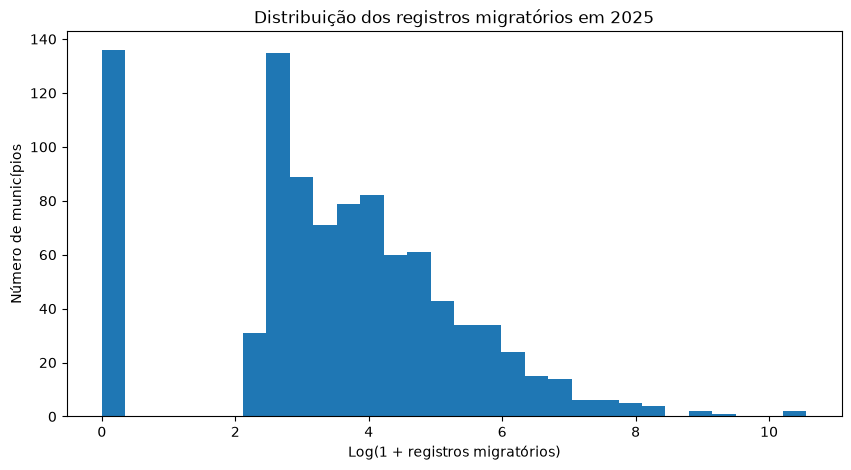

In [109]:
# Plot de registros migratórios 

# Histograma com transformação logarítmica
np.log1p(indicadores_integrados["2025"].dropna()).plot(
    kind="hist",
    bins=30,
    figsize=(10, 5)
)

plt.title("Distribuição dos registros migratórios em 2025")
plt.xlabel("Log(1 + registros migratórios)")
plt.ylabel("Número de municípios")
plt.show()

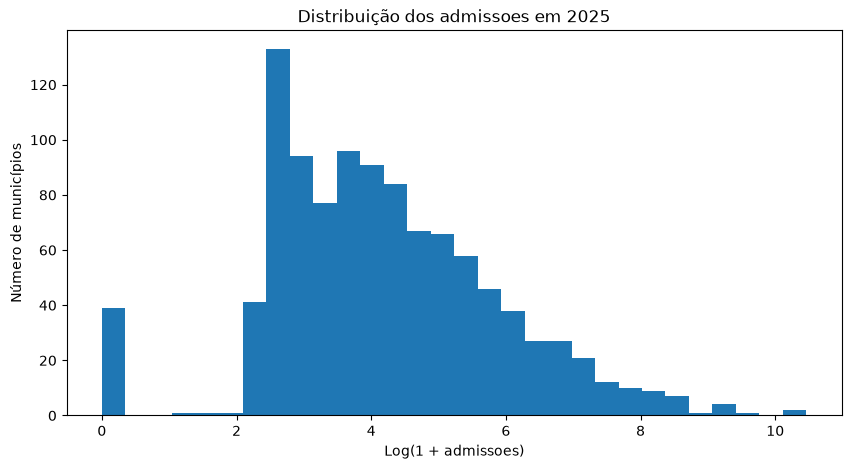

In [110]:
np.log1p(indicadores_integrados["admissoes"].dropna()).plot(
    kind="hist",
    bins=30,
    figsize=(10, 5)
)

plt.title("Distribuição dos admissoes em 2025")
plt.xlabel("Log(1 + admissoes)")
plt.ylabel("Número de municípios")
plt.show()

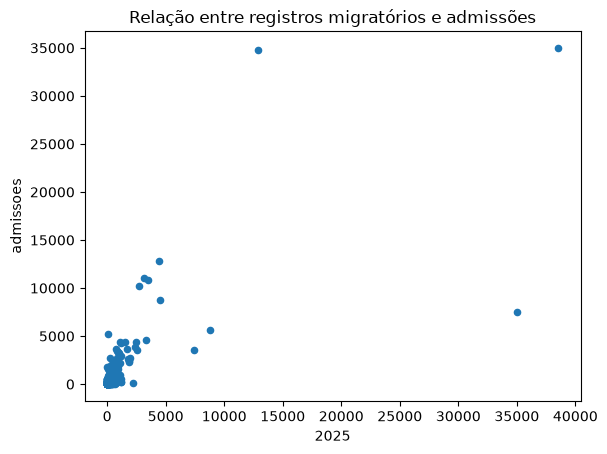

In [111]:
# Investigando a relação entre migração e emprego 

indicadores_integrados.plot(
    kind="scatter",
    x='2025',
    y='admissoes',
)

plt.title("Relação entre registros migratórios e admissões")
plt.show()

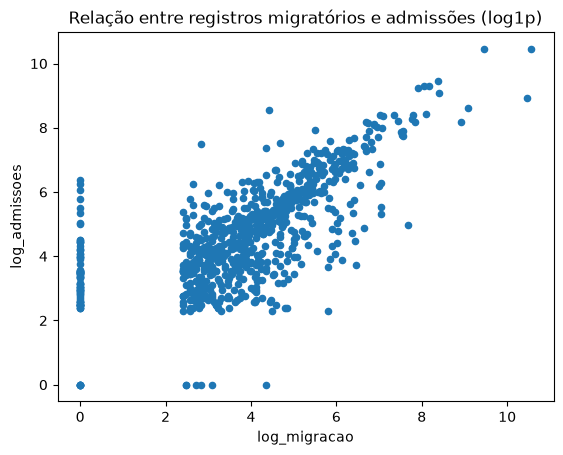

In [112]:
indicadores_integrados['log_migracao'] = np.log1p(indicadores_integrados['2025'])

indicadores_integrados['log_admissoes'] = np.log1p(indicadores_integrados['admissoes'])


indicadores_integrados.plot(
    kind="scatter",
    x='log_migracao',
    y='log_admissoes',
)

plt.title("Relação entre registros migratórios e admissões (log1p)")
plt.show()

### Calcular a correlação
Agora vamos quantificar essa associação utilizando o coeficiente de correlação de Pearson.

Ele varia de -1 a +1:
- Próximo de +1: associação linear positiva forte.
- Próximo de 0: pouca associação linear.
- Próximo de -1: associação linear negativa forte.
Como estamos investigando a relação observada no gráfico, vamos calcular a correlação entre as duas variáveis transformadas.

In [113]:
correlacao = indicadores_integrados[
    ["log_migracao", "log_admissoes"]
].corr()

display(correlacao)

,log_migracao,log_admissoes
log_migracao,1.000000,0.694214
log_admissoes,0.694214,1.000000


In [114]:
correlacao_2 = indicadores_integrados[
    ["2025", "admissoes"]
].corr()

display(correlacao_2)

,2025,admissoes
2025,1.000000,0.737113
admissoes,0.737113,1.000000


In [115]:
correlacao_spearman = indicadores_integrados[
    ["2025", "admissoes"]
].corr(method='spearman')

display(correlacao_spearman)

,2025,admissoes
2025,1.000000,0.699864
admissoes,0.699864,1.000000


In [116]:
correlacao_saldo_spearman = indicadores_integrados[
    ["2025", "saldo"]
].corr(method='spearman')

display(correlacao_saldo_spearman)

,2025,saldo
2025,1.000000,0.557984
saldo,0.557984,1.000000


In [117]:
correlacao_admissoes_saldo_spearman = indicadores_integrados[
    ["admissoes", "saldo"]
].corr(method='spearman')

display(correlacao_admissoes_saldo_spearman)

,admissoes,saldo
admissoes,1.00000,0.73616
saldo,0.73616,1.00000


In [118]:
# Visualizando os arquivos de educacao

import pandas as pd
from pathlib import Path

pasta = Path("../data/raw/educacao")

for arquivo in pasta.rglob("*.csv"):
    print(arquivo.name)

Tabela_Curso_Tecnico_2025_V2.csv
Tabela_Docente_2025_V2.csv
Tabela_Escola_2025_V2.csv
Tabela_Gestor_Escolar_2025_v2.csv
Tabela_Matricula_2025_V2.csv
Tabela_Turma_2025_V2.csv
MICRODADOS_CADASTRO_CURSOS_2024.CSV
MICRODADOS_ED_SUP_IES_2024.CSV
